# Imports

In [2]:
import os, sys
sys.path.append("D:\\DATA\\ETL_PIC\\simulation\\")
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
matplotlib.rc_file('D:\\DATA\\ETL_PIC\\matplotlibrc.txt')
import pandas as pd
from tqdm import tqdm

import rsoft_lib as rlib
from rsoft_lib.device_setup import SIM, DESIGN_WAVELENGTH, WIDTH, device_paths, export_device

# Design device

For generating a wave of Euler bends, we use the ```euler_wave()``` function to generate the delay arm in terms of ```n_periods``` (number of cycles in the wave), ```step``` (lateral amplitude of the wave), ```R_min``` (minimum radius of the Euler bend), ```z_length``` (length of the wave along the z-axis, extended with straights as needed), and ```p``` (Euler fraction).

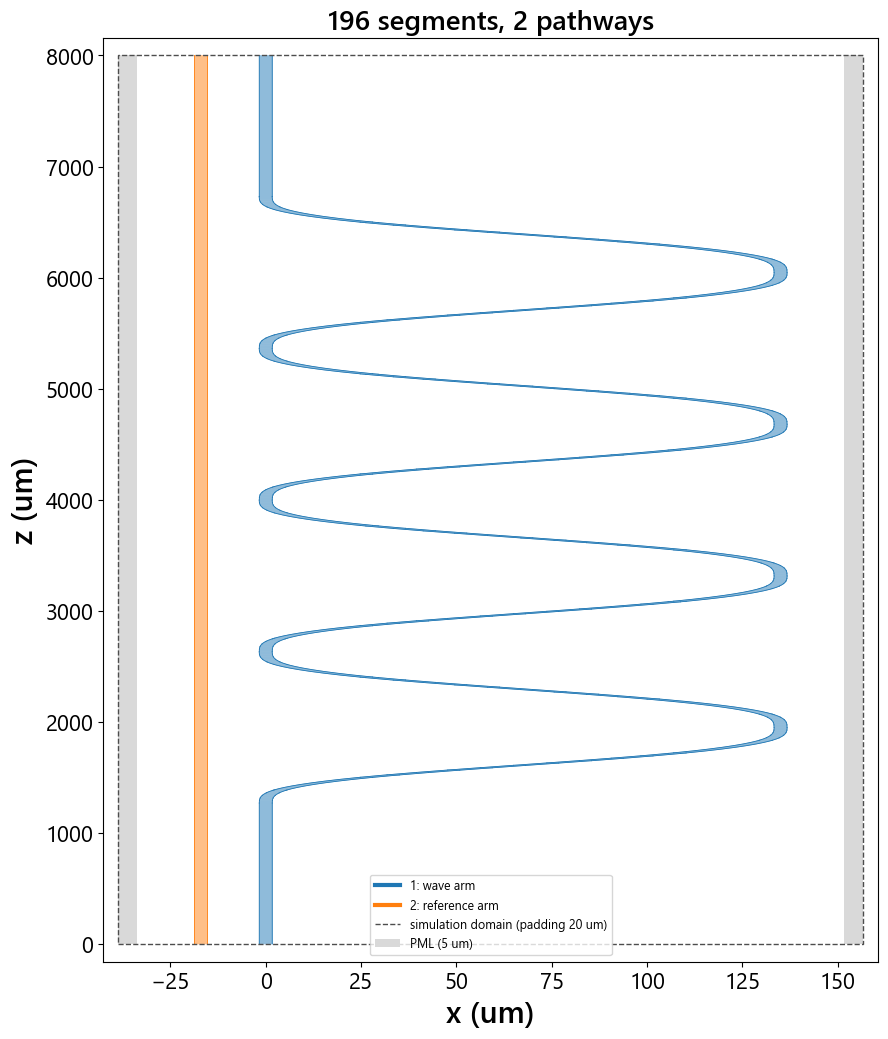

P-06a_BendPhaseMZI: wave arm - reference arm = 159.7676 μm (wave 159.7674 μm), 195 segments, fitted to 14.9 nm
Wrote D:\DATA\ETL_PIC\simulation\NullingPIC_Gen2_sims\P-06_BendPhaseMZI\P-06a_BendPhaseMZI.ind and D:\DATA\ETL_PIC\simulation\NullingPIC_Gen2_sims\P-06_BendPhaseMZI\P-06a_BendPhaseMZI.gds; 80000 propagation steps per wavelength


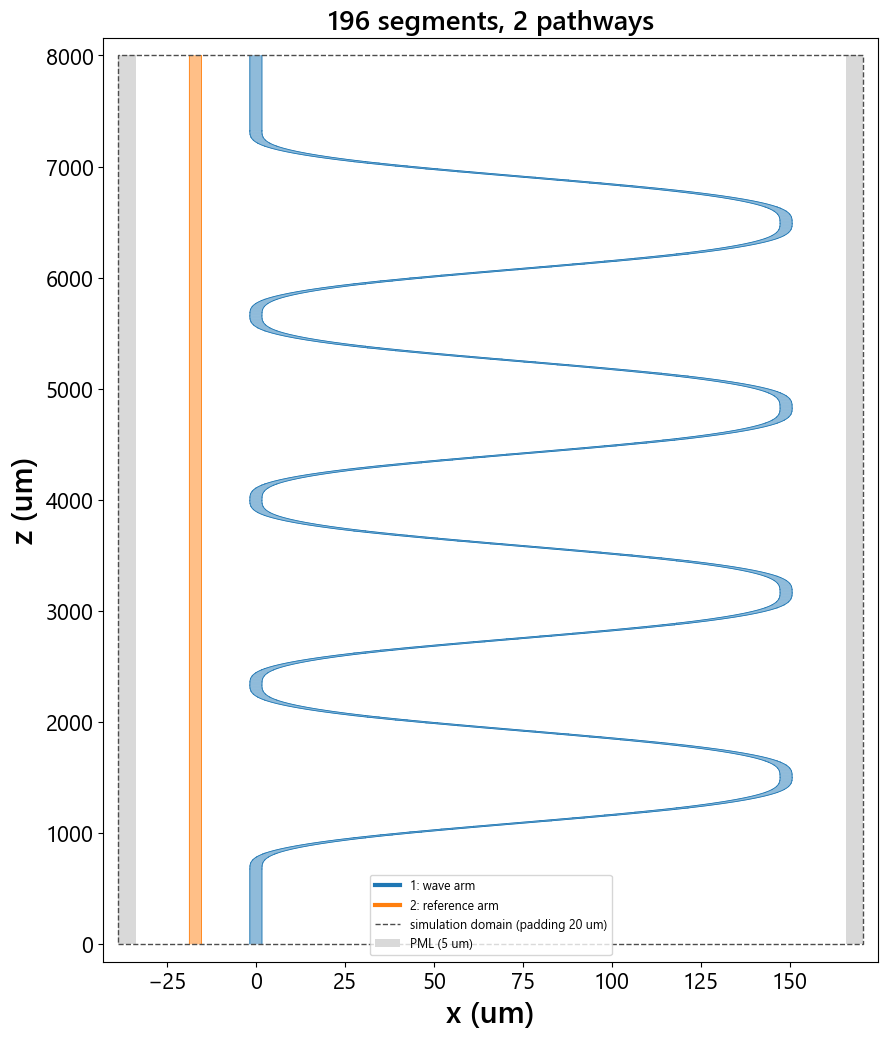

P-06b_BendPhaseMZI: wave arm - reference arm = 160.0228 μm (wave 160.0226 μm), 195 segments, fitted to 14.4 nm
Wrote D:\DATA\ETL_PIC\simulation\NullingPIC_Gen2_sims\P-06_BendPhaseMZI\P-06b_BendPhaseMZI.ind and D:\DATA\ETL_PIC\simulation\NullingPIC_Gen2_sims\P-06_BendPhaseMZI\P-06b_BendPhaseMZI.gds; 80000 propagation steps per wavelength


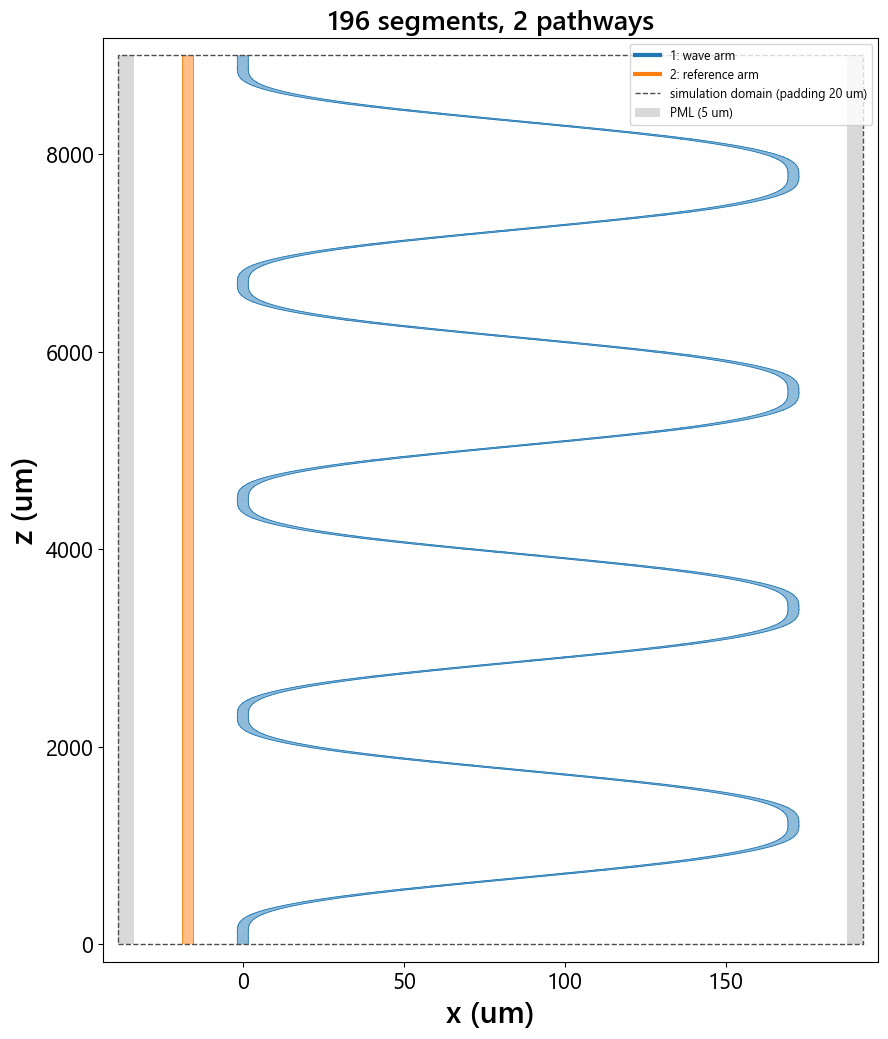

P-06c_BendPhaseMZI: wave arm - reference arm = 160.1767 μm (wave 160.1766 μm), 195 segments, fitted to 14.6 nm
Wrote D:\DATA\ETL_PIC\simulation\NullingPIC_Gen2_sims\P-06_BendPhaseMZI\P-06c_BendPhaseMZI.ind and D:\DATA\ETL_PIC\simulation\NullingPIC_Gen2_sims\P-06_BendPhaseMZI\P-06c_BendPhaseMZI.gds; 90000 propagation steps per wavelength


In [6]:
# Set up directories
device_name = 'P-06_BendPhaseMZI'
device_dir = f"D:\\DATA\\ETL_PIC\\simulation\\NullingPIC_Gen2_sims\\{device_name}\\"

# Set up parameters: (periods, lateral step (um), minimum radius (um), z length (um)) of each variant's Euler wave
variants = {
    "P-06a_BendPhaseMZI": (4, 135.0, 600.0, 8000.0),
    "P-06b_BendPhaseMZI": (4, 149.0, 800.0, 8000.0),
    "P-06c_BendPhaseMZI": (4, 171.0, 1200.0, 9000.0),
}
euler_p = 0.5                   # Euler fraction of each S-bend of the wave
arm_pitch = 17.0                # reference arm, this far on the -x side of the wave arm (um)
fit_tol = 0.015                 # accuracy of the arcs fitted to the wave (um): 15 nm keeps a wave under RSoft's 200 segments per pathway
pathway_labels = ["wave arm", "reference arm"]

circuits = {}
for variant_name, (n_periods, step, R_min, z_length) in variants.items():
    paths = device_paths(device_dir, variant_name)

    # Define the arms: the Euler wave arm and a straight reference arm of the same z length
    x, z, phi, wave = rlib.euler_wave(n_periods, step, R_min, z_length=z_length, p=euler_p, return_params=True)
    xs = np.vstack([x, -arm_pitch * np.ones_like(x)])
    zs = np.vstack([z, z])
    phis = np.vstack([phi, np.zeros_like(phi)])

    # Define circuit: one pathway per arm, both launched; every segment extended
    c, info = rlib.paths_to_circuit(xs, zs, phis, width=WIDTH, tol=fit_tol, orientation="extended")
    circuits[variant_name] = c

    # Export and visualize circuit
    export_device(c, paths)
    c.plot(labels=pathway_labels, figsize=(10, 12))      # after the export, so the plot shows the domain as written
    dL = c.path_length(c.pathways[0].segments) - c.path_length(c.pathways[1].segments)
    print(f"{variant_name}: wave arm - reference arm = {dL:.4f} μm (wave {wave['deltaL']:.4f} μm), {len(c.pathways[0].segments)} segments, "
          f"fitted to {info[0]['max_deviation'] * 1e3:.1f} nm")
    print(f"Wrote {paths['ind']} and {paths['gds']}; {z_length / SIM['Step_z']:.0f} propagation steps per wavelength")

# Estimate interference pattern

D:\DATA\ETL_PIC\simulation\rsoft_lib\StraightWaveguide_simulatedBend_neff_table\StraightWaveguide_simulatedBend_neff.csv not found: building the bend n_eff table from the .nef files in D:\DATA\ETL_PIC\simulation\rsoft_lib\StraightWaveguide_simulatedBend_neff_table


D:\DATA\ETL_PIC\simulation\rsoft_lib\simulation.py:420: UserWarning: Pathway 1: 3 um of bends have a radius outside the bend table (300-25000 um); above it the n_eff shift is continued as 1/R^2 and the loss log-linearly (1 arcs above, the rest below, where the value at 300 um is used).
  warnings.warn(f"Pathway {number}: {est.extrapolated_length:.0f} um of bends have a radius outside the bend table "


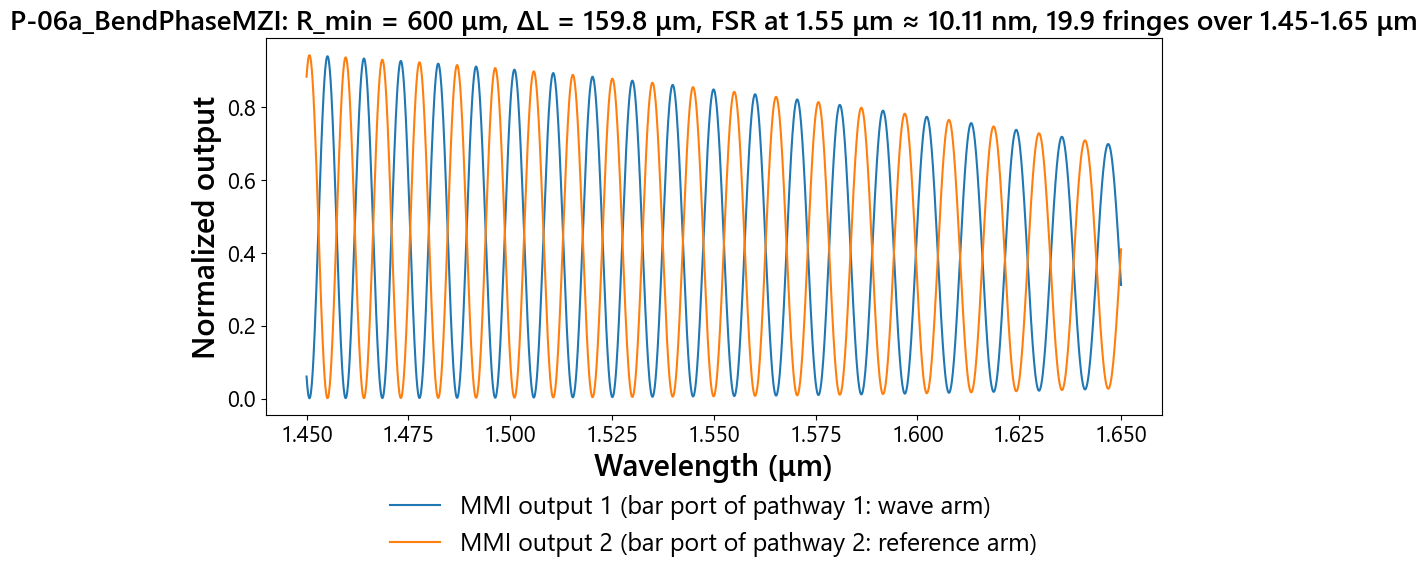

D:\DATA\ETL_PIC\simulation\rsoft_lib\simulation.py:420: UserWarning: Pathway 1: 7 um of bends have a radius outside the bend table (300-25000 um); above it the n_eff shift is continued as 1/R^2 and the loss log-linearly (1 arcs above, the rest below, where the value at 300 um is used).
  warnings.warn(f"Pathway {number}: {est.extrapolated_length:.0f} um of bends have a radius outside the bend table "


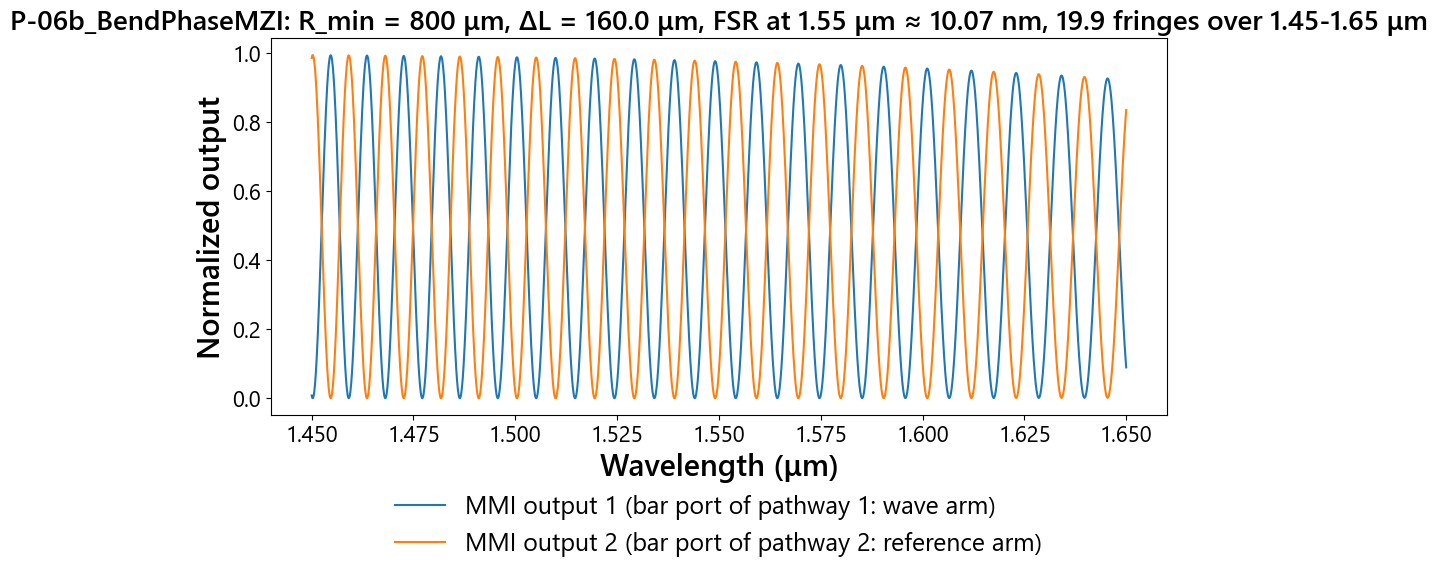

D:\DATA\ETL_PIC\simulation\rsoft_lib\simulation.py:420: UserWarning: Pathway 1: 288 um of bends have a radius outside the bend table (300-25000 um); above it the n_eff shift is continued as 1/R^2 and the loss log-linearly (9 arcs above, the rest below, where the value at 300 um is used).
  warnings.warn(f"Pathway {number}: {est.extrapolated_length:.0f} um of bends have a radius outside the bend table "


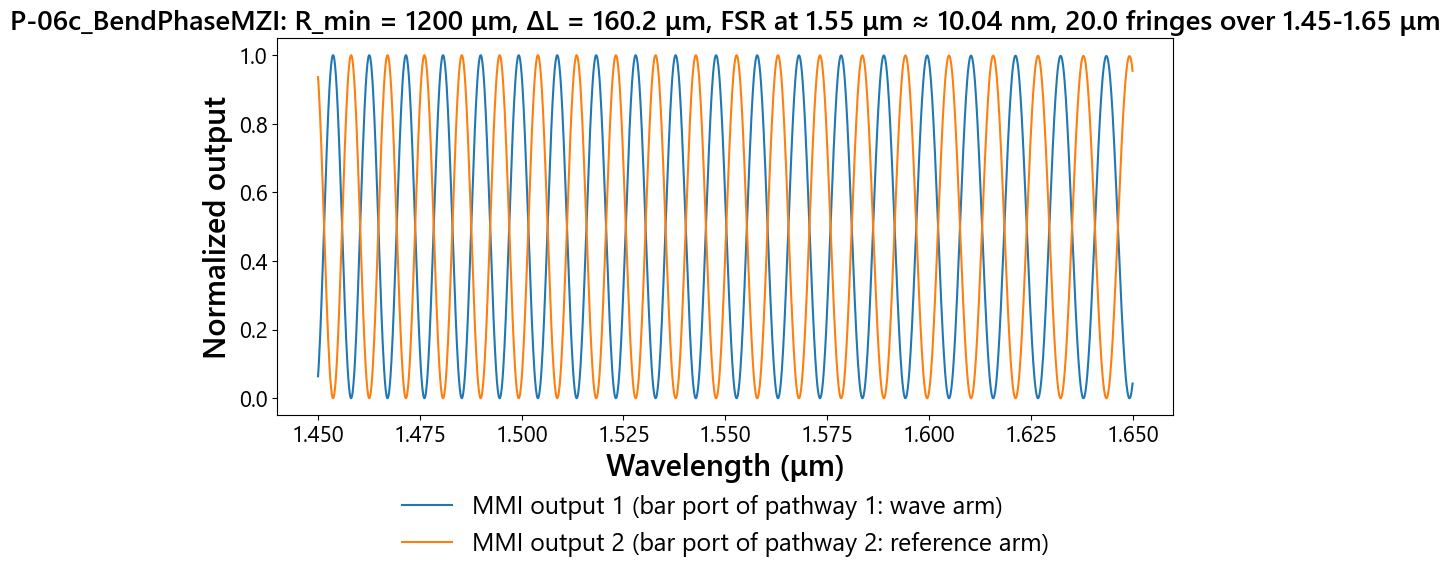

In [7]:
# %% Interference spectrum of each circuit: Y-splitter, the two pathways, 2x2 MMI
wl = np.linspace(1.45, 1.65, 2001)
tm = rlib.transfer

for variant_name, c in circuits.items():
    n_periods, step, R_min, z_length = variants[variant_name]
    est = rlib.estimate_pathways(c, wl)
    arm_a = tm.pathway(est, 1)                          # pathway 1: wave arm
    arm_b = tm.pathway(est, 2)                          # pathway 2: reference arm
    T = tm.mzi_response(wl, arm_a, arm_b, splitter="y", combiner="mmi")
    P = tm.power(T)                                     # (wavelengths, 2 outputs)
    dphi = est.difference(1, 2)["phase"]                # wave arm - reference arm
    n_fringes = abs(dphi[0] - dphi[-1]) / (2 * np.pi)
    fsr = tm.fsr(wl, dphi)

    plt.figure(figsize=(10, 6))
    plt.plot(wl, P[:, 0], label=f"MMI output 1 (bar port of pathway 1: {pathway_labels[0]})")
    plt.plot(wl, P[:, 1], label=f"MMI output 2 (bar port of pathway 2: {pathway_labels[1]})")
    plt.xlabel('Wavelength (μm)')
    plt.ylabel('Normalized output')
    plt.title(f"{variant_name}: R_min = {R_min:g} μm, ΔL = {est.difference(1, 2)['length']:.1f} μm, "
              f"FSR at 1.55 μm ≈ {np.interp(1.55, wl, fsr) * 1e3:.2f} nm, {n_fringes:.1f} fringes over {wl[0]:g}-{wl[-1]:g} μm")
    plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=1, frameon=False)
    plt.tight_layout()
    plt.show()